In [1]:
# 第一部分：导入必要的库（电脑B）
# ============================================

import mindspore as ms
from mindspore import nn
import mindspore.dataset as ds
import mindspore.ops as P
from mindspore.nn import SoftmaxCrossEntropyWithLogits
from mindspore.common.initializer import Normal

import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split

from mindquantum.core.circuit import Circuit, UN
from mindquantum.core.gates import H, RY, RZ, CNOT, Rxx, Ryy, Rzz
from mindquantum.core.parameterresolver import PRGenerator
from mindquantum.core.operators import QubitOperator, Hamiltonian
from mindquantum.simulator import Simulator
from mindquantum.framework import MQLayer
from mindspore import Tensor
import warnings
warnings.filterwarnings('ignore')

# 设置中文字体支持
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

[WARNING] ME(34696:34504,MainProcess):2026-10-05-01:43:40.530.00 [mindspore\run_check\_check_version.py:543] The directory C:\Program Files\NVIDIA GPU Computing Toolkit\CUDA\v12.4 does not contain the typical file structure of CUDA
[ERROR] ME(34696:34504,MainProcess):2026-10-05-01:43:40.540.00 [mindspore\run_check\_check_version.py:582] CUDA_PATH C:\Program Files\NVIDIA GPU Computing Toolkit\CUDA\v12.4 is not safe, skip add cuda path.


In [2]:
# 第二部分：可调参数配置区（电脑B - PCA + 测量后权重实验）
# ============================================

# 数据相关参数
SAMPLE_RATIO = 1            # 数据采样比例
TEST_SIZE = 0.2                # 测试集比例
PCA_COMPONENTS = 8             # PCA降维维度（与量子比特数一致）
BATCH_SIZE = 32                 # 批处理大小

# 降维方法固定为PCA
DIM_REDUCTION_METHOD = 'pca'    # 固定降维方法

# 量子电路参数
NUM_QUBITS = 8                  # 量子比特数
FIXED_ANSAYZ_TYPE = 'sequential_su4'  # 固定Ansatz类型
FIXED_LAYERS = 2                 # 固定层数

# 测量后权重类型（替代原缩放层）
WEIGHT_TYPES = ['scalar', 'diagonal', 'full']  # 三种权重类型

# 训练参数
NUM_EPOCHS = 150                 # 训练轮数
LEARNING_RATE = 0.01             # 学习率
PARALLEL_WORKER = 2              # 并行工作器数量

# MindSpore配置
MS_MODE = ms.PYNATIVE_MODE        # 运行模式
MS_DEVICE = "CPU"                 # 设备目标
SEED = 42                         # 随机种子

# 初始化设置
# ============================================
ms.set_context(mode=MS_MODE, device_target=MS_DEVICE)
ms.set_seed(SEED)
np.random.seed(SEED)

[WARNING] ME(34696:34504,MainProcess):2026-10-05-01:43:53.806.000 [mindspore\context.py:1334] For 'context.set_context', the parameter 'device_target' will be deprecated and removed in a future version. Please use the api mindspore.set_device() instead.


In [3]:
# 第三部分：数据加载和处理函数（电脑B - PCA降维）
# ============================================

from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
import mindspore.dataset as ds

def load_mnist_data():
    """加载MNIST数据集（与之前相同）"""
    import os
    from torchvision.datasets import MNIST
    
    print("正在下载/加载MNIST数据集...")
    data_dir = "./MNIST"
    os.makedirs(data_dir, exist_ok=True)
    
    try:
        train_set = MNIST(data_dir, train=True, download=True)
        test_set = MNIST(data_dir, train=False, download=True)
    except:
        import tempfile
        temp_dir = tempfile.gettempdir()
        data_dir = os.path.join(temp_dir, "MNIST")
        print(f"使用临时目录: {data_dir}")
        train_set = MNIST(data_dir, train=True, download=True)
        test_set = MNIST(data_dir, train=False, download=True)
    
    def extract_data(dataset):
        images = dataset.data.numpy().astype(np.float32) / 255.0
        labels = dataset.targets.numpy()
        images_flatten = images.reshape(len(images), -1)
        return images_flatten, labels
    
    train_images, train_labels = extract_data(train_set)
    test_images, test_labels = extract_data(test_set)
    
    # 合并数据并采样
    all_images = np.concatenate([train_images, test_images])
    all_labels = np.concatenate([train_labels, test_labels])
    sampled_indices = np.random.choice(
        len(all_images), 
        int(len(all_images) * SAMPLE_RATIO), 
        replace=False
    )
    sampled_images = all_images[sampled_indices]
    sampled_labels = all_labels[sampled_indices]
    
    print(f"总样本数: {len(all_images)}, 采样后: {len(sampled_images)}")
    print(f"类别分布: {np.unique(sampled_labels, return_counts=True)}")
    
    return sampled_images, sampled_labels

def preprocess_data_pca(images, labels, scaler=None, pca=None, is_train=True):
    """
    PCA降维 + 归一化到[-1,1]预处理函数
    返回: (dataset, scaler, pca)
    """
    if is_train:
        # 训练集：训练PCA和Scaler
        pca = PCA(n_components=PCA_COMPONENTS)
        pca_data = pca.fit_transform(images)
        print(f"PCA解释方差比: {np.sum(pca.explained_variance_ratio_):.4f}")
        
        # 归一化到[-1, 1]
        scaler = MinMaxScaler(feature_range=(-1, 1))
        normalized_data = scaler.fit_transform(pca_data)
    else:
        # 测试集：使用训练好的模型
        pca_data = pca.transform(images)
        normalized_data = scaler.transform(pca_data)
    
    # 创建MindSpore数据集
    dataset = ds.NumpySlicesDataset(
        data=(normalized_data.astype(np.float32), labels.astype(np.int32)),
        column_names=["features", "labels"],
        shuffle=is_train
    ).batch(BATCH_SIZE)
    
    return dataset, scaler, pca

In [4]:
# 第四部分：量子电路构建函数（通用）
# ============================================

def build_encoder():
    """构建编码器电路（固定）"""
    prg = PRGenerator('alpha')
    encoder = Circuit()
    encoder += UN(H, NUM_QUBITS)
    
    for i in range(NUM_QUBITS):
        encoder += RY(prg.new()).on(i)
    
    # 局部 Brickwall 纠缠（一层即可）
    for i in range(0, NUM_QUBITS - 1, 2):
        encoder += CNOT.on(i + 1, i)
    for i in range(1, NUM_QUBITS - 1, 2):
        encoder += CNOT.on(i + 1, i)
    
    encoder = encoder.no_grad()
    encoder.as_encoder()
    return encoder

def build_sequential_su4_ansatz(num_layers):
    """构建顺序SU4 Ansatz（固定使用此结构）"""
    theta_prg = PRGenerator('theta')
    ansatz = Circuit()
    
    for layer in range(num_layers):
        # 单比特旋转层
        for qubit in range(NUM_QUBITS):
            ansatz += RY(theta_prg.new()).on(qubit)
            ansatz += RZ(theta_prg.new()).on(qubit)
        
        # 顺序两比特门层
        for i in range(NUM_QUBITS - 1):
            ansatz += Rxx(theta_prg.new()).on([i, i + 1])
            ansatz += Ryy(theta_prg.new()).on([i, i + 1])
            ansatz += Rzz(theta_prg.new()).on([i, i + 1])
            
            ansatz += RY(theta_prg.new()).on(i)
            ansatz += RZ(theta_prg.new()).on(i)
            ansatz += RY(theta_prg.new()).on(i + 1)
            ansatz += RZ(theta_prg.new()).on(i + 1)
    
    # 最终单比特层
    for qubit in range(NUM_QUBITS):
        ansatz += RZ(theta_prg.new()).on(qubit)
        ansatz += RY(theta_prg.new()).on(qubit)
    
    ansatz.as_ansatz()
    return ansatz

def build_ansatz():
    """根据固定参数构建Ansatz"""
    return build_sequential_su4_ansatz(FIXED_LAYERS)

def create_hamiltonians():
    """创建测量哈密顿量 - 仅测量单比特Z"""
    hams = []
    for i in range(NUM_QUBITS):
        hams.append(Hamiltonian(QubitOperator(f'Z{i}', 1.0)))
    return hams

In [5]:
# 第五部分：神经网络定义与训练（修改后：测量后权重）
# ============================================

class LearnableWeight(nn.Cell):
    """测量后可学习的权重层（对量子测量输出进行线性变换）"""
    def __init__(self, input_dim=NUM_QUBITS, weight_type="diagonal"):
        super(LearnableWeight, self).__init__()
        self.weight_type = weight_type
        self.input_dim = input_dim
        
        if weight_type == "scalar":
            # 标量权重：所有维度共享同一个缩放因子和偏置
            self.weight = ms.Parameter(Tensor(np.ones(1) * 1.0, dtype=ms.float32))
            self.bias = ms.Parameter(Tensor(np.zeros(1), dtype=ms.float32))
            print(f"  权重类型: 标量权重 (1个权重参数)")
            
        elif weight_type == "diagonal":
            # 对角权重：每个维度有自己的缩放因子和偏置
            self.weight = ms.Parameter(Tensor(np.ones(input_dim) * 1.0, dtype=ms.float32))
            self.bias = ms.Parameter(Tensor(np.zeros(input_dim), dtype=ms.float32))
            print(f"  权重类型: 对角权重 ({input_dim}个权重参数)")
            
        elif weight_type == "full":
            # 全连接权重：线性变换
            self.linear = nn.Dense(input_dim, input_dim, has_bias=True)
            print(f"  权重类型: 全连接权重 ({input_dim * input_dim + input_dim}个参数)")
        else:
            raise ValueError(f"未知的权重类型: {weight_type}")
    
    def construct(self, x):
        if self.weight_type == "scalar":
            return x * self.weight + self.bias
        elif self.weight_type == "diagonal":
            return x * self.weight + self.bias
        elif self.weight_type == "full":
            return self.linear(x)
        return x


class HybridQuantumNet(nn.Cell):
    """混合量子-经典神经网络（含测量后权重层 + ReLU 激活）"""
    def __init__(self, quantum_net, weight_type, num_classes=10):
        super(HybridQuantumNet, self).__init__()
        self.quantum_net = quantum_net
        
        # 测量后可学习权重层
        self.weight_layer = LearnableWeight(NUM_QUBITS, weight_type)
        
        # ★ 新增：ReLU 激活函数（在测量后权重层与全连接层之间）
        self.relu = nn.ReLU()
        
        # 分类层（输入维度 = 量子比特数，输出维度 = 类别数）
        self.fc = nn.Dense(NUM_QUBITS, num_classes, weight_init=Normal(0.02))
        
    def construct(self, x):
        # 确保输入为二维 [batch_size, features]
        if len(x.shape) == 1:
            x = x.reshape(1, -1)
        elif len(x.shape) > 2:
            x = x.reshape(x.shape[0], -1)
        
        # 量子层输出Z测量值，形状 [batch_size, NUM_QUBITS]
        quantum_out = self.quantum_net(x)
        
        # 应用可学习权重层
        quantum_out = self.weight_layer(quantum_out)
        
        # ★ 新增：ReLU 激活（引入非线性，使权重层具备更强的特征变换能力）
        quantum_out = self.relu(quantum_out)
        
        # 分类
        logits = self.fc(quantum_out)
        return logits


def train_model(train_dataset, val_dataset, weight_type,
                num_epochs=NUM_EPOCHS, learning_rate=LEARNING_RATE):
    """
    训练模型（固定使用 sequential_su4, 2层，但测量后权重类型可变）
    参数：
        train_dataset: 训练数据集
        val_dataset: 验证数据集
        weight_type: 权重类型，如 'scalar', 'diagonal', 'full'
    """
    print(f"\n开始训练: Ansatz类型={FIXED_ANSAYZ_TYPE}, 层数={FIXED_LAYERS}, 权重类型={weight_type}")
    
    # 构建量子电路
    print("构建量子电路...")
    encoder = build_encoder()
    ansatz = build_ansatz()  # 使用固定层数
    full_circuit = encoder + ansatz
    
    print("量子电路构建完成:")
    print(f"  编码器: {encoder.n_qubits}量子比特")
    print(f"  Ansatz: {ansatz.n_qubits}量子比特，{FIXED_LAYERS}层")
    
    # 创建哈密顿量和梯度算子（仅Z测量）
    print("创建哈密顿量和梯度算子...")
    hams = create_hamiltonians()
    print(f"  哈密顿量数量: {len(hams)} (单比特Z)")
    
    sim = Simulator('mqvector', NUM_QUBITS)
    grad_ops = sim.get_expectation_with_grad(
        hams, full_circuit, parallel_worker=PARALLEL_WORKER
    )
    
    # 创建量子层和混合网络
    print("创建神经网络...")
    quantum_net = MQLayer(grad_ops)
    net = HybridQuantumNet(quantum_net, weight_type=weight_type, num_classes=10)
    
    # 损失函数和优化器
    loss_fn = SoftmaxCrossEntropyWithLogits(sparse=True, reduction='mean')
    optimizer = nn.Adam(net.trainable_params(), learning_rate=learning_rate)
    
    # 定义前向传播和梯度函数
    def forward_fn(data, label):
        if len(data.shape) == 1:
            data = data.reshape(1, -1)
        logits = net(data)
        loss = loss_fn(logits, label)
        return loss, logits
    
    grad_fn = ms.value_and_grad(forward_fn, None, optimizer.parameters, has_aux=True)
    
    # 训练循环
    train_losses = []
    val_accuracies = []
    best_val_acc = 0.0
    
    print(f"\n开始训练循环 ({num_epochs} epochs)...")
    
    for epoch in range(num_epochs):
        # 训练
        net.set_train()
        epoch_loss = 0
        step = 0
        
        for data, label in train_dataset.create_tuple_iterator():
            (loss, _), grads = grad_fn(data, label)
            optimizer(grads)
            epoch_loss += loss.asnumpy()
            step += 1
        
        avg_loss = epoch_loss / step if step > 0 else 0
        train_losses.append(avg_loss)
        
        # 验证
        net.set_train(False)
        correct = 0
        total = 0
        
        for data, label in val_dataset.create_tuple_iterator():
            if len(data.shape) == 1:
                data = data.reshape(1, -1)
            logits = net(data)
            predict = ms.ops.Argmax(output_type=ms.int32)(logits)
            correct += (predict == label).asnumpy().sum()
            total += len(label)
        
        val_acc = correct / total if total > 0 else 0
        val_accuracies.append(val_acc)
        
        if val_acc > best_val_acc:
            best_val_acc = val_acc
        
        # 打印进度
        if (epoch + 1) % 10 == 0 or epoch == 0 or epoch == num_epochs - 1:
            print(f"Epoch {epoch+1:3d}/{num_epochs}: "
                  f"训练损失={avg_loss:.4f}, 验证准确率={val_acc:.4f}")
    
    print(f"\n训练完成! 最佳验证准确率: {best_val_acc:.4f}")
    
    return train_losses, val_accuracies, best_val_acc

PCA降维 + 测量后可学习权重(带ReLU)实验 - 固定Ansatz: sequential_su4, 层数=2

步骤1：加载MNIST数据
正在下载/加载MNIST数据集...
总样本数: 70000, 采样后: 70000
类别分布: (array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=int64), array([6903, 7877, 6990, 7141, 6824, 6313, 6876, 7293, 6825, 6958],
      dtype=int64))
数据大小: 70000

步骤2：划分训练集和测试集
训练集: 56000 样本, 测试集: 14000 样本

步骤3：PCA降维预处理
PCA解释方差比: 0.4384
PCA降维和归一化完成，数据集已准备好。

实验: 权重类型 = scalar (含 ReLU 激活)

开始训练: Ansatz类型=sequential_su4, 层数=2, 权重类型=scalar
构建量子电路...
量子电路构建完成:
  编码器: 8量子比特
  Ansatz: 8量子比特，2层
创建哈密顿量和梯度算子...
  哈密顿量数量: 8 (单比特Z)
创建神经网络...
  权重类型: 标量权重 (1个权重参数)

开始训练循环 (150 epochs)...
Epoch   1/150: 训练损失=0.8264, 验证准确率=0.7814
Epoch  10/150: 训练损失=0.5842, 验证准确率=0.8175
Epoch  20/150: 训练损失=0.5496, 验证准确率=0.8339
Epoch  30/150: 训练损失=0.5300, 验证准确率=0.8349
Epoch  40/150: 训练损失=0.5247, 验证准确率=0.8296
Epoch  50/150: 训练损失=0.5228, 验证准确率=0.8321
Epoch  60/150: 训练损失=0.5224, 验证准确率=0.8331
Epoch  70/150: 训练损失=0.5223, 验证准确率=0.8311
Epoch  80/150: 训练损失=0.5222, 验证准确率=0.8306
Epoch  90/150: 训练损失=0.5216, 验证准确率=0.

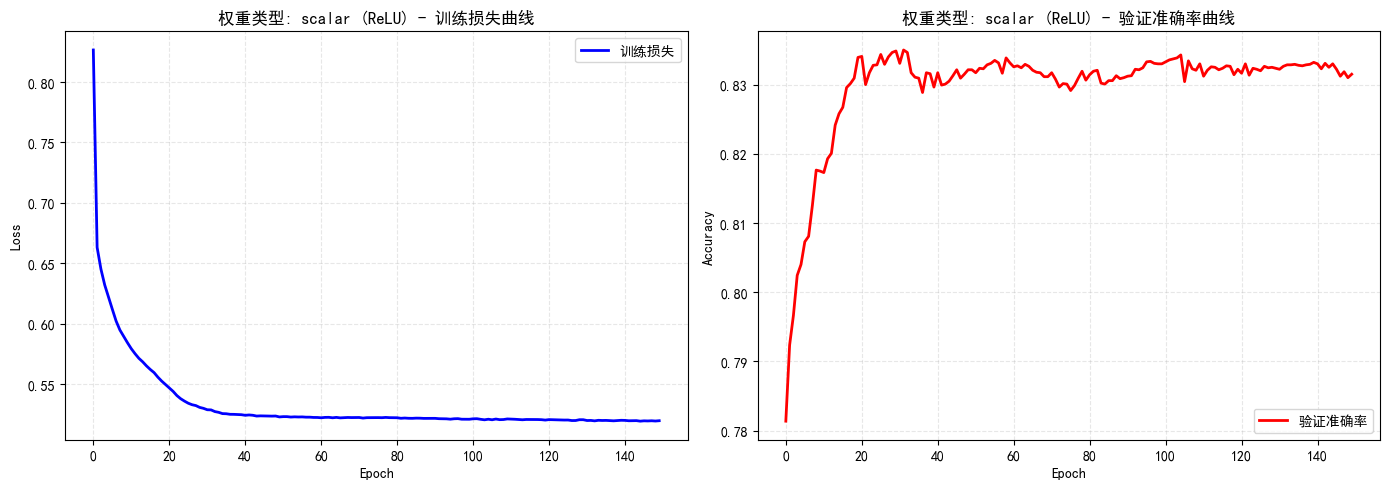


实验: 权重类型 = diagonal (含 ReLU 激活)

开始训练: Ansatz类型=sequential_su4, 层数=2, 权重类型=diagonal
构建量子电路...
量子电路构建完成:
  编码器: 8量子比特
  Ansatz: 8量子比特，2层
创建哈密顿量和梯度算子...
  哈密顿量数量: 8 (单比特Z)
创建神经网络...
  权重类型: 对角权重 (8个权重参数)

开始训练循环 (150 epochs)...
Epoch   1/150: 训练损失=1.0265, 验证准确率=0.7460
Epoch  10/150: 训练损失=0.5826, 验证准确率=0.8135
Epoch  20/150: 训练损失=0.5480, 验证准确率=0.8292
Epoch  30/150: 训练损失=0.5344, 验证准确率=0.8411
Epoch  40/150: 训练损失=0.5296, 验证准确率=0.8449
Epoch  50/150: 训练损失=0.5281, 验证准确率=0.8456
Epoch  60/150: 训练损失=0.5270, 验证准确率=0.8449
Epoch  70/150: 训练损失=0.5265, 验证准确率=0.8441
Epoch  80/150: 训练损失=0.5263, 验证准确率=0.8444
Epoch  90/150: 训练损失=0.5262, 验证准确率=0.8434
Epoch 100/150: 训练损失=0.5261, 验证准确率=0.8435
Epoch 110/150: 训练损失=0.5260, 验证准确率=0.8436
Epoch 120/150: 训练损失=0.5261, 验证准确率=0.8434
Epoch 130/150: 训练损失=0.5260, 验证准确率=0.8435
Epoch 140/150: 训练损失=0.5259, 验证准确率=0.8434
Epoch 150/150: 训练损失=0.5260, 验证准确率=0.8435

训练完成! 最佳验证准确率: 0.8457


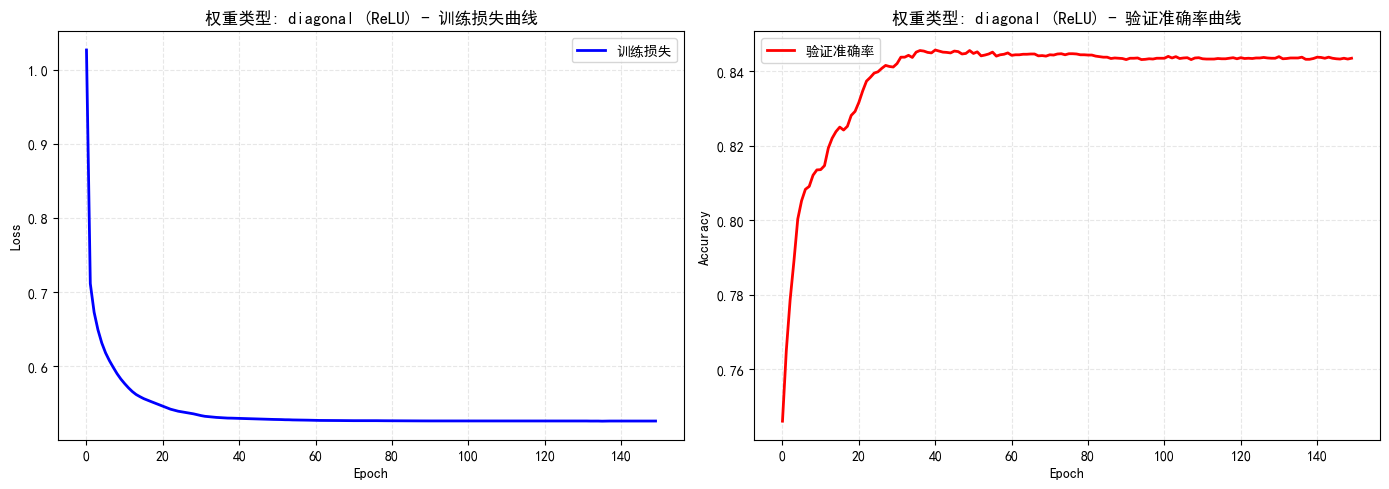


实验: 权重类型 = full (含 ReLU 激活)

开始训练: Ansatz类型=sequential_su4, 层数=2, 权重类型=full
构建量子电路...
量子电路构建完成:
  编码器: 8量子比特
  Ansatz: 8量子比特，2层
创建哈密顿量和梯度算子...
  哈密顿量数量: 8 (单比特Z)
创建神经网络...
  权重类型: 全连接权重 (72个参数)

开始训练循环 (150 epochs)...
Epoch   1/150: 训练损失=1.0244, 验证准确率=0.7686
Epoch  10/150: 训练损失=0.5219, 验证准确率=0.8299
Epoch  20/150: 训练损失=0.4986, 验证准确率=0.8319
Epoch  30/150: 训练损失=0.4941, 验证准确率=0.8409
Epoch  40/150: 训练损失=0.4906, 验证准确率=0.8371
Epoch  50/150: 训练损失=0.4870, 验证准确率=0.8438
Epoch  60/150: 训练损失=0.4861, 验证准确率=0.8408
Epoch  70/150: 训练损失=0.4822, 验证准确率=0.8434
Epoch  80/150: 训练损失=0.4808, 验证准确率=0.8426
Epoch  90/150: 训练损失=0.4791, 验证准确率=0.8427
Epoch 100/150: 训练损失=0.4796, 验证准确率=0.8448
Epoch 110/150: 训练损失=0.4798, 验证准确率=0.8434
Epoch 120/150: 训练损失=0.4800, 验证准确率=0.8439
Epoch 130/150: 训练损失=0.4798, 验证准确率=0.8441
Epoch 140/150: 训练损失=0.4801, 验证准确率=0.8440
Epoch 150/150: 训练损失=0.4793, 验证准确率=0.8433

训练完成! 最佳验证准确率: 0.8454


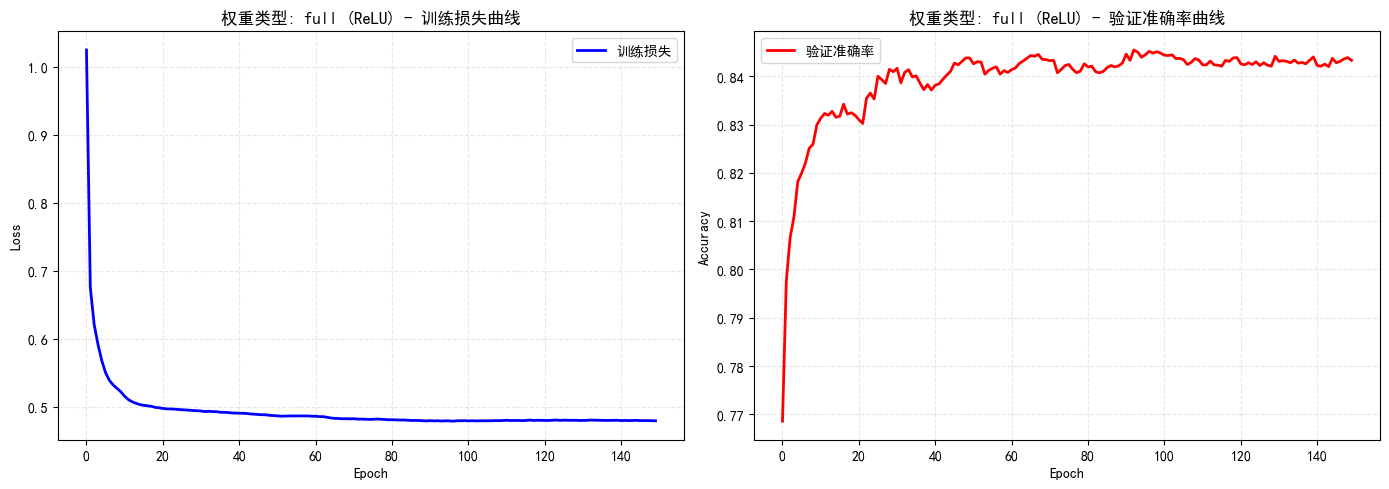


实验结果汇总 (PCA + 测量后权重 + ReLU)
scalar    : 最佳验证准确率 = 0.8350
diagonal  : 最佳验证准确率 = 0.8457
full      : 最佳验证准确率 = 0.8454

所有结果已保存到 post_measure_weight_relu_results.npz


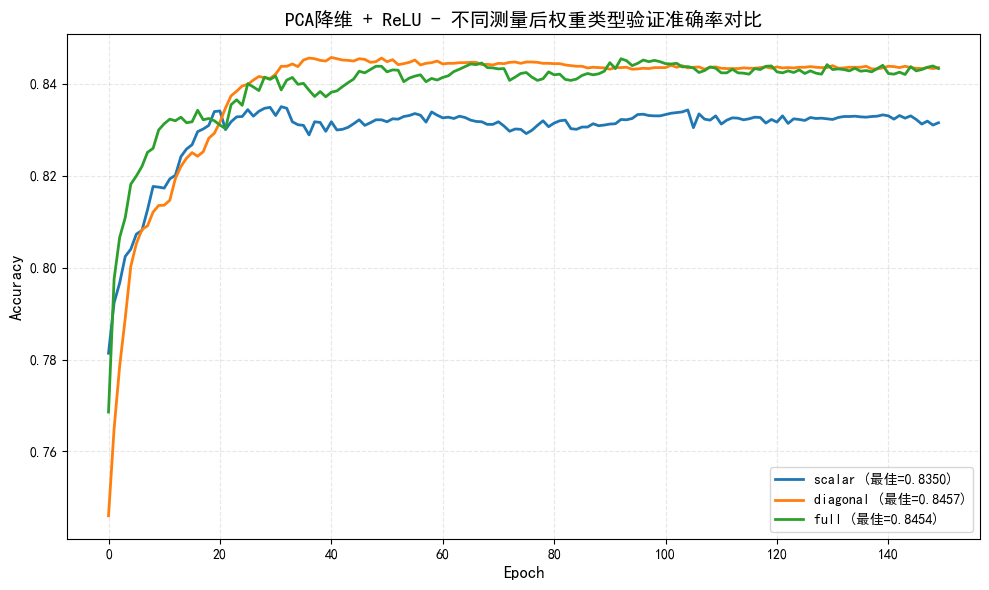

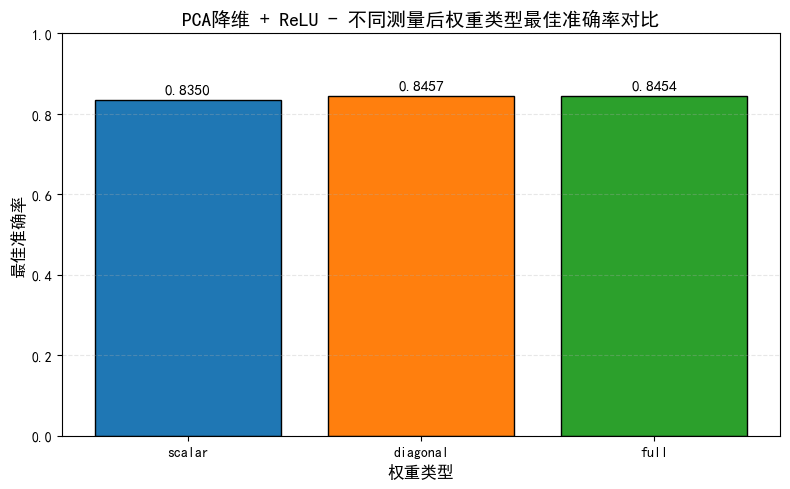

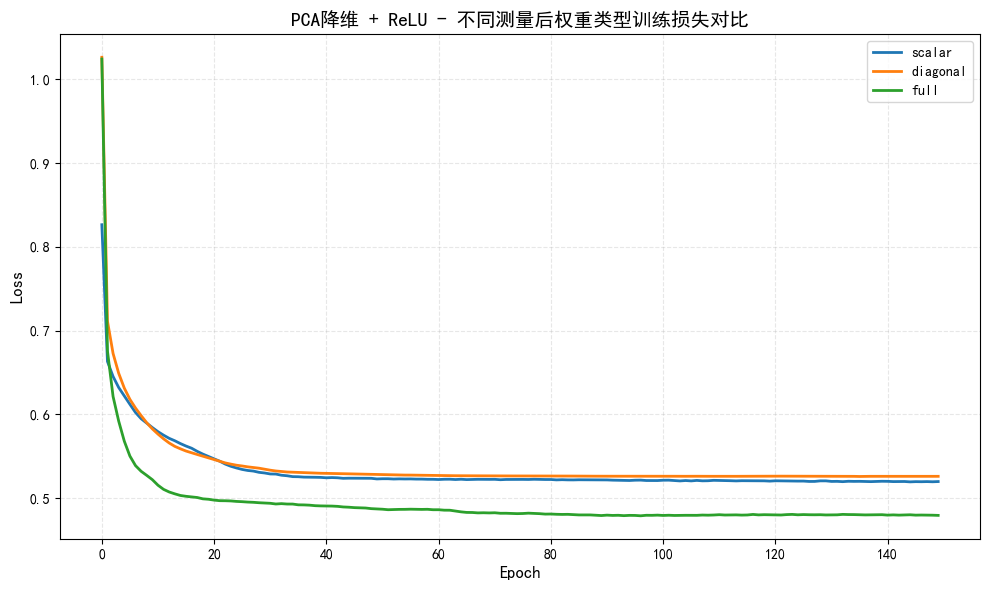

In [6]:
# 第六部分：主程序 - PCA降维 + 测量后权重实验（带 ReLU 激活）
# ============================================

if __name__ == "__main__":
    print("=" * 60)
    print("PCA降维 + 测量后可学习权重(带ReLU)实验 - 固定Ansatz: sequential_su4, 层数=2")
    print("=" * 60)

    # 1. 加载数据
    print("\n步骤1：加载MNIST数据")
    all_images, all_labels = load_mnist_data()
    print(f"数据大小: {len(all_images)}")

    # 2. 划分数据集
    print("\n步骤2：划分训练集和测试集")
    train_images, test_images, train_labels, test_labels = train_test_split(
        all_images, all_labels, test_size=TEST_SIZE, random_state=SEED, stratify=all_labels
    )
    print(f"训练集: {len(train_images)} 样本, 测试集: {len(test_images)} 样本")

    # 3. 一次性完成PCA降维预处理，得到训练和测试数据集
    print("\n步骤3：PCA降维预处理")
    train_dataset, scaler, pca = preprocess_data_pca(
        train_images, train_labels, is_train=True
    )
    test_dataset, _, _ = preprocess_data_pca(
        test_images, test_labels, scaler=scaler, pca=pca, is_train=False
    )
    print("PCA降维和归一化完成，数据集已准备好。")

    # 4. 遍历三种权重类型进行实验
    all_results = {}  # 键为 weight_type

    for weight_type in WEIGHT_TYPES:
        print(f"\n{'='*60}")
        print(f"实验: 权重类型 = {weight_type} (含 ReLU 激活)")
        print(f"{'='*60}")

        # 训练模型
        train_losses, val_accuracies, best_val_acc = train_model(
            train_dataset=train_dataset,
            val_dataset=test_dataset,
            weight_type=weight_type,
            num_epochs=NUM_EPOCHS,
            learning_rate=LEARNING_RATE
        )

        # 存储结果
        all_results[weight_type] = {
            'train_losses': train_losses,
            'val_accuracies': val_accuracies,
            'best_val_acc': best_val_acc
        }

        # 5. 绘制单个实验的曲线（更清晰）
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        # 训练损失
        axes[0].plot(train_losses, 'b-', linewidth=2, label='训练损失')
        axes[0].set_title(f'权重类型: {weight_type} (ReLU) - 训练损失曲线', fontsize=12)
        axes[0].set_xlabel('Epoch')
        axes[0].set_ylabel('Loss')
        axes[0].grid(True, alpha=0.3, linestyle='--')
        axes[0].legend()
        # 验证准确率
        axes[1].plot(val_accuracies, 'r-', linewidth=2, label='验证准确率')
        axes[1].set_title(f'权重类型: {weight_type} (ReLU) - 验证准确率曲线', fontsize=12)
        axes[1].set_xlabel('Epoch')
        axes[1].set_ylabel('Accuracy')
        axes[1].grid(True, alpha=0.3, linestyle='--')
        axes[1].legend()
        plt.tight_layout()
        plt.show()

    # 6. 汇总结果（清晰表格打印）
    print("\n" + "=" * 60)
    print("实验结果汇总 (PCA + 测量后权重 + ReLU)")
    print("=" * 60)
    for weight_type, res in all_results.items():
        print(f"{weight_type:10s}: 最佳验证准确率 = {res['best_val_acc']:.4f}")

    # 7. 保存所有结果（ReLU 版本，新文件名）
    np.savez('post_measure_weight_relu_results.npz',
             weight_types=WEIGHT_TYPES,
             train_losses={wt: all_results[wt]['train_losses'] for wt in WEIGHT_TYPES},
             val_accuracies={wt: all_results[wt]['val_accuracies'] for wt in WEIGHT_TYPES},
             best_val_accs={wt: all_results[wt]['best_val_acc'] for wt in WEIGHT_TYPES})
    print("\n所有结果已保存到 post_measure_weight_relu_results.npz")

    # 8. 绘制所有权重类型的对比曲线（综合）
    plt.figure(figsize=(10, 6))
    for weight_type in WEIGHT_TYPES:
        plt.plot(all_results[weight_type]['val_accuracies'], 
                 label=f'{weight_type} (最佳={all_results[weight_type]["best_val_acc"]:.4f})', 
                 linewidth=2)
    plt.title('PCA降维 + ReLU - 不同测量后权重类型验证准确率对比', fontsize=14)
    plt.xlabel('Epoch', fontsize=12)
    plt.ylabel('Accuracy', fontsize=12)
    plt.legend(loc='lower right')
    plt.grid(True, alpha=0.3, linestyle='--')
    plt.tight_layout()
    plt.show()

    # 9. 绘制最佳准确率柱状图（带误差说明）
    plt.figure(figsize=(8, 5))
    best_accs = [all_results[wt]['best_val_acc'] for wt in WEIGHT_TYPES]
    bars = plt.bar(WEIGHT_TYPES, best_accs, color=['#1f77b4', '#ff7f0e', '#2ca02c'], edgecolor='black')
    plt.title('PCA降维 + ReLU - 不同测量后权重类型最佳准确率对比', fontsize=14)
    plt.xlabel('权重类型', fontsize=12)
    plt.ylabel('最佳准确率', fontsize=12)
    plt.ylim(0, 1.0)
    for bar, acc in zip(bars, best_accs):
        plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, 
                 f'{acc:.4f}', ha='center', va='bottom', fontsize=11)
    plt.grid(axis='y', alpha=0.3, linestyle='--')
    plt.tight_layout()
    plt.show()

    # 10. 绘制训练损失对比曲线（可选，增加全面性）
    plt.figure(figsize=(10, 6))
    for weight_type in WEIGHT_TYPES:
        plt.plot(all_results[weight_type]['train_losses'], 
                 label=f'{weight_type}', linewidth=2)
    plt.title('PCA降维 + ReLU - 不同测量后权重类型训练损失对比', fontsize=14)
    plt.xlabel('Epoch', fontsize=12)
    plt.ylabel('Loss', fontsize=12)
    plt.legend()
    plt.grid(True, alpha=0.3, linestyle='--')
    plt.tight_layout()
    plt.show()